In [1]:
import os
import json
import pandas as pd


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [2]:
# ls

In [3]:
base_path = "../results_auto_threshold/calibration_rerankers"


df = pd.read_csv(
    f"{base_path}/zscore_margin_calibration_Qwen_Qwen3-Reranker-4B.csv"
)


In [4]:
# ls

In [5]:
df[df["k"] == 3]

,router,model_name,k,threshold,accuracy,fallback_rate,specialist_recall,general_recall,balanced_accuracy,recall_gap
0,cross-encoder,Qwen/Qwen3-Reranker-4B,3,0,0.4396,0.0000,0.9756,0.00,0.4878,0.9756
1,cross-encoder,Qwen/Qwen3-Reranker-4B,3,5,0.4396,0.0000,0.9756,0.00,0.4878,0.9756
2,cross-encoder,Qwen/Qwen3-Reranker-4B,3,10,0.4396,0.0000,0.9756,0.00,0.4878,0.9756
3,cross-encoder,Qwen/Qwen3-Reranker-4B,3,15,0.4396,0.0000,0.9756,0.00,0.4878,0.9756
4,cross-encoder,Qwen/Qwen3-Reranker-4B,3,20,0.4396,0.0000,0.9756,0.00,0.4878,0.9756
5,cross-encoder,Qwen/Qwen3-Reranker-4B,3,25,0.4396,0.0000,0.9756,0.00,0.4878,0.9756
6,cross-encoder,Qwen/Qwen3-Reranker-4B,3,30,0.4396,0.0000,0.9756,0.00,0.4878,0.9756
7,cross-encoder,Qwen/Qwen3-Reranker-4B,3,35,0.4396,0.0000,0.9756,0.00,0.4878,0.9756
8,cross-encoder,Qwen/Qwen3-Reranker-4B,3,40,0.4396,0.0000,0.9756,0.00,0.4878,0.9756
9,cross-encoder,Qwen/Qwen3-Reranker-4B,3,45,0.4396,0.0000,0.9756,0.00,0.4878,0.9756


In [10]:
# df[df["k"]== 3].sort_values(by="accuracy", ascending=False)

In [11]:
# best_per_k = df.loc[
#     df.groupby("k")["accuracy"].idxmax()
# ][[
#     "k",
#     "threshold",
#     "accuracy",
#     "general_recall",
#     "specialist_recall",
#     "fallback_rate"
# ]]

# best_per_k

In [12]:
# global_threshold = (
#     df[df["k"] >= 5]
# #     df
#     .groupby("threshold")[
#         [
#             "accuracy",
#             "general_recall",
#             "specialist_recall",
#             "fallback_rate",
#         ]
#     ]
#     .mean()
#     .round(4)
# )

In [13]:
# global_threshold.sort_values(by="accuracy", ascending=False)

,Model,Intercept,Scale / slope,SSE,R²
0,Affine: a+b·ln(√(k−1)),105.7637,-26.6946,11.90,0.952


,k value,threshold,Affine: a+b·ln(√(k−1))
0,3,95,96.51
1,5,90,87.26
2,8,80,79.79
3,10,75,76.44


,k (curve),Affine: a+b·ln(√(k−1))
0,3.00,96.51
1,3.25,94.94
2,3.50,93.53
3,3.75,92.26
4,4.00,91.10
5,4.25,90.03
6,4.50,89.04
7,4.75,88.12
8,5.00,87.26
9,5.25,86.45


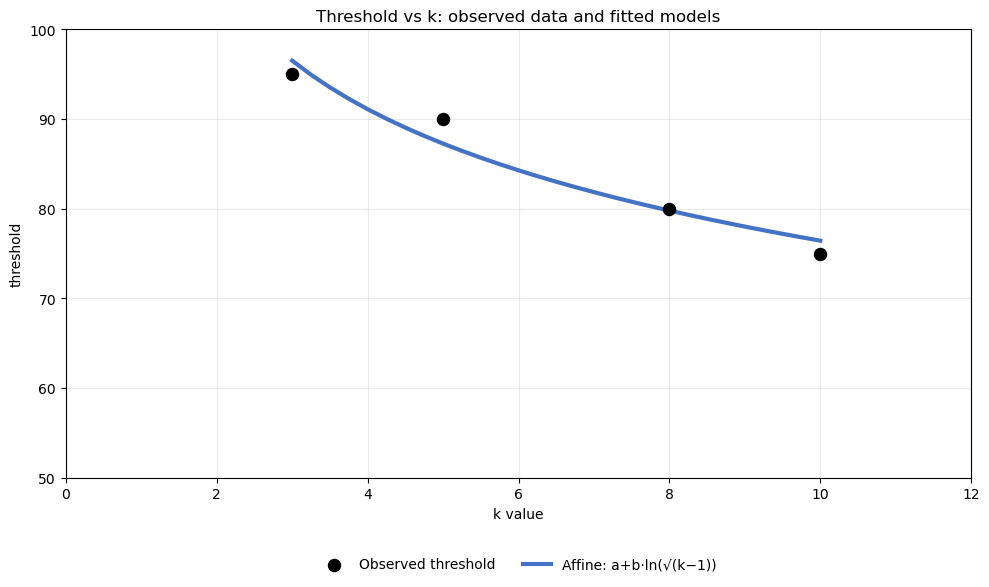

In [16]:
# %% [markdown]
# # Threshold model comparison
# This notebook reproduces the data, five fitted models, diagnostics, curve table, and chart from Excel.
 
# %% Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
 
# %% Observed data from Sheet1!A2:B5
observed = pd.DataFrame({
'k value': [3,5,8,10],
# 'threshold': [95, 80, 70, 60], # # BAAI/bge-large-en-v1.5
    
# 'threshold': [90, 85, 75, 70], # Qwen/Qwen3-Embedding-4B
'threshold': [95, 90, 80, 75], # Qwen/Qwen3-Reranker-4B
    
# 'threshold': [95, 90, 85, 85], # mixedbread-ai/mxbai-rerank-large-v2
})
k = observed['k value'].to_numpy(dtype=float)
y = observed['threshold'].to_numpy(dtype=float)
 
# %% Helper functions
def fit_through_origin(x, y):
    return np.dot(x, y) / np.dot(x, x)
 
def diagnostics(y, y_hat):
    sse = np.sum((y - y_hat) ** 2)
    r2 = 1 - sse / np.sum((y - y.mean()) ** 2)
    return sse, r2
 
# %% Transformations used by the Excel formulas
x_direct = np.sqrt(k - 1)
x_inverse = 1 / np.sqrt(k - 1)
x_log_sqrt = np.log(np.sqrt(k - 1))
x_log = np.log(k - 1)
 
# %% Fit the four proportional models (intercept fixed at zero)
a_direct = fit_through_origin(x_direct, y)
a_inverse = fit_through_origin(x_inverse, y)
a_log_sqrt = fit_through_origin(x_log_sqrt, y)
a_log = fit_through_origin(x_log, y)
 
# Fit y = intercept + slope * ln(sqrt(k - 1))
slope_affine, intercept_affine = np.polyfit(x_log_sqrt, y, 1)
 
models = {
# 'Direct: a√(k−1)': (0.0, a_direct, lambda z: a_direct * np.sqrt(z - 1)),
# 'Inverse: a/√(k−1)': (0.0, a_inverse, lambda z: a_inverse / np.sqrt(z - 1)),
# 'Proportional: a·ln(√(k−1))': (0.0, a_log_sqrt, lambda z: a_log_sqrt * np.log(np.sqrt(z - 1))),
# 'Proportional: a·ln(k−1)': (0.0, a_log, lambda z: a_log * np.log(z - 1)),
'Affine: a+b·ln(√(k−1))': (intercept_affine, slope_affine, lambda z: intercept_affine + slope_affine * np.log(np.sqrt(z - 1))),
}
 
# %% Model summary matching Sheet1!F1:J6
summary_rows = []
for name, (intercept, scale, predict) in models.items():
    sse, r2 = diagnostics(y, predict(k))
    summary_rows.append({
        'Model': name,
        'Intercept': intercept,
        'Scale / slope': scale,
        'SSE': sse,
        'R²': r2,
    })
    
model_summary = pd.DataFrame(summary_rows)
display(model_summary.style.format({
'Intercept': '{:.4f}',
'Scale / slope': '{:.4f}',
'SSE': '{:.2f}',
'R²': '{:.3f}',
}))
 
# %% Observed-point fitted values matching Sheet1!C:D and R:T
observed_fits = observed.copy()
for name, (_, _, predict) in models.items():
    observed_fits[name] = predict(k)
    display(observed_fits.style.format(precision=2))
 
# %% Curve grid matching Sheet1!K2:P30
    k_curve = np.arange(3.0, 10.0 + 0.25, 0.25)
    curve_data = pd.DataFrame({'k (curve)': k_curve})
for name, (_, _, predict) in models.items():
    curve_data[name] = predict(k_curve)
    display(curve_data.style.format(precision=2))
 
# %% Chart
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(k, y, s=75, color='black', label='Observed threshold', zorder=5)
colors = ['#4472C4', '#ED7D31', '#70AD47', '#A5A5A5', '#7030A0']
for (name, (_, _, predict)), color in zip(models.items(), colors):
    width = 3.0 if name.startswith('Affine') else 1.8
    ax.plot(k_curve, predict(k_curve), label=name, color=color, linewidth=width)

    ax.set_title('Threshold vs k: observed data and fitted models')
    ax.set_xlabel('k value')
    ax.set_ylabel('threshold')
    ax.set_xlim(0, 12)
    ax.set_ylim(50, 100)
    ax.grid(True, alpha=0.25)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
    fig.tight_layout()
    plt.show()
 
# %% Optional: save notebook outputs
model_summary.to_csv('model_summary.csv', index=False)
curve_data.to_csv('threshold_model_curves.csv', index=False)
fig.savefig('threshold_model_comparison.png', dpi=150, bbox_inches='tight', facecolor='white')

In [1]:
# # %% Imports
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# # %% Fit p*(K) = a * ln(sqrt(K - 1)) + b
# def fit_curve(ks, ps):
#     x = np.log(np.sqrt(np.asarray(ks, float) - 1))
#     y = np.asarray(ps, float)
#     a, b = np.polyfit(x, y, 1)                          # a = slope, b = intercept
#     r2 = 1 - np.sum((y - (a * x + b)) ** 2) / np.sum((y - y.mean()) ** 2)
#     return a, b, r2

# def curve(K, a, b):
#     return a * np.log(np.sqrt(np.asarray(K, float) - 1)) + b

# # %% Thresholds picked from the MMLU reranker calibration sweep
# points = {
#     "balanced":   ([3, 5, 8, 10], [95, 90, 75, 70]),   # spec recall ≈ gen recall
# #     "specialist": ([3, 5, 8, 10], [95, 90, 60, 55]),   # highest p with spec recall ≥ 0.90
# #     "general":    ([5, 8, 10],    [90, 80, 75]),       # lowest p with gen recall ≥ 0.90 (K=3 excluded)
# }
# fits = {name: fit_curve(ks, ps) for name, (ks, ps) in points.items()}
# print(pd.DataFrame(fits, index=["a (slope)", "b (intercept)", "R²"]).T.round(4))

# # %% Plot all three curves with their points
# k_curve = np.arange(3, 14.25, 0.25)
# fig, ax = plt.subplots(figsize=(9, 5))
# for name, (a, b, _) in fits.items():
#     line, = ax.plot(k_curve, curve(k_curve, a, b), label=name)
#     ax.scatter(*points[name], color=line.get_color(), zorder=5)
# ax.set(xlabel="K (number of specialists)", ylabel="required % of z_max", ylim=(40, 100))
# ax.grid(alpha=0.3)
# ax.legend()
# plt.show()
# fig.savefig("threshold_curves.png", dpi=150, bbox_inches="tight")

# # %% Values to use in the router / MedMCQA table
# a_bal, b_bal = fits["balanced"][:2]
# a_spec, b_spec = fits["specialist"][:2]
# a_gen, b_gen = fits["general"][:2]